In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("student_dropout_risk_2026.csv")
df.shape

(100000, 34)

In [50]:
df[["age", "attendance_rate", "gpa_semester_2"]].describe()

,age,attendance_rate,gpa_semester_2
count,100000.000000,100000.000000,100000.000000
mean,21.520840,75.102136,1.980795
std,3.399468,17.425800,0.717822
min,15.000000,0.000000,0.000000
25%,19.000000,63.100000,1.490000
50%,21.000000,76.100000,1.990000
75%,24.000000,89.000000,2.490000
max,30.000000,100.000000,4.000000


In [51]:
x = [4, 8, 6, 5, 3, 7, 9, 5, 6, 7]
n = len(x)
mean = sum(x) / n
ss = sum((v - mean) ** 2 for v in x)
std = (ss / (n - 1)) ** 0.5
print(mean, ss, std)
print(pd.Series(x).std())

6.0 30.0 1.8257418583505538
1.8257418583505538


In [52]:
df.groupby("family_income_level")["gpa_semester_2"].mean()

family_income_level
High      2.160601
Low       1.829202
Middle    2.000331
Name: gpa_semester_2, dtype: float64

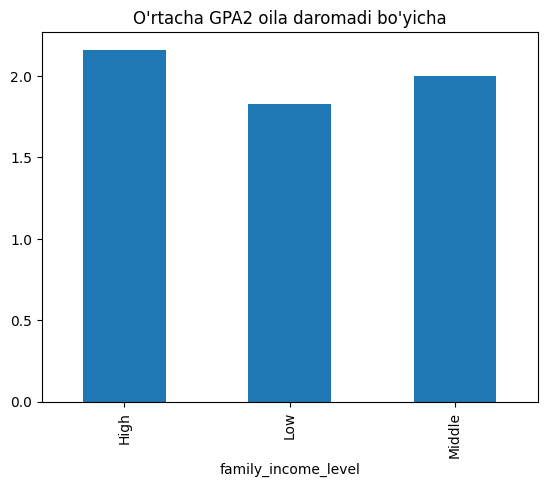

In [53]:
df.groupby("family_income_level")["gpa_semester_2"].mean().plot(kind="bar")
plt.title("O'rtacha GPA2 oila daromadi bo'yicha")
plt.show()

In [54]:
a = df["attendance_rate"]
b = df["gpa_semester_2"]
da, db = a - a.mean(), b - b.mean()
r = (da * db).sum() / ((da**2).sum() * (db**2).sum()) ** 0.5
print(r, a.corr(b))

0.22234572906534958 0.2223457290653497


In [55]:
col = df["commute_time_mins"]
print("min:", col.min())
print("max:", col.max())
print("median:", col.median())
print("o'rtacha:", round(col.mean(), 2))

min: 0
max: 120
median: 16.0
o'rtacha: 23.26


In [56]:
q1 = col.quantile(0.25)
q3 = col.quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
outliers = col[(col < low) | (col > high)]
print("Q1:", q1, " Q3:", q3, " IQR:", iqr)
print("Pastki chegara:", low, " Yuqori chegara:", high)
print("Outlierlar soni:", len(outliers))

Q1: 6.0  Q3: 33.0  IQR: 27.0
Pastki chegara: -34.5  Yuqori chegara: 73.5
Outlierlar soni: 4879


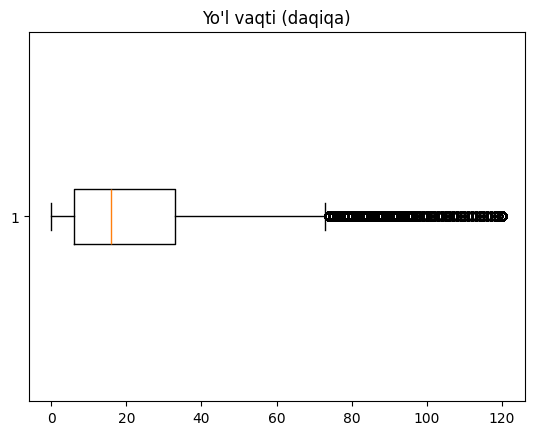

In [57]:
plt.boxplot(col, vert=False)
plt.title("Yo'l vaqti (daqiqa)")
plt.show()

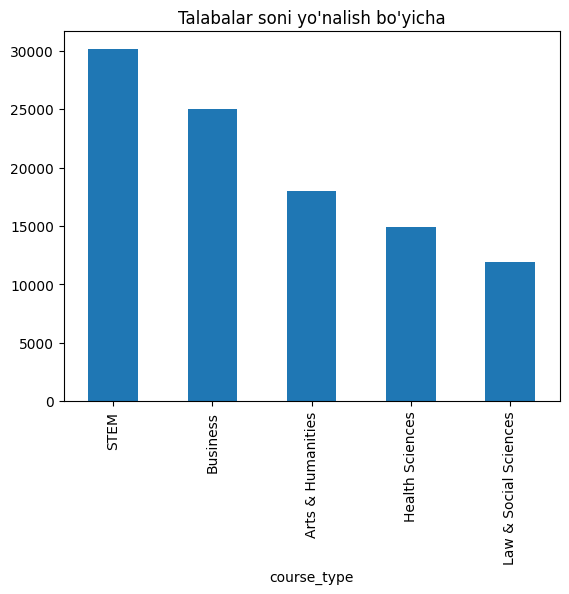

In [58]:
df["course_type"].value_counts().plot(kind="bar")
plt.title("Talabalar soni yo'nalish bo'yicha")
plt.show()

In [ ]:
#Qatorlar — yo’nalishlar, ustunlar — oila daromadi
pv = pd.pivot_table(df, values="dropout", index="course_type",
                    columns="family_income_level", aggfunc="mean")
pv

family_income_level,High,Low,Middle
course_type,,,
Arts & Humanities,0.199556,0.434268,0.295675
Business,0.200868,0.425221,0.299921
Health Sciences,0.197930,0.426862,0.307179
Law & Social Sciences,0.193174,0.426492,0.302316
STEM,0.202999,0.431553,0.298714
